# NLP Lab 5 — Language Models, N-grams และ RNN

---

## วิธีใช้ Notebook นี้

| สัญลักษณ์ | ความหมาย |
|---|---|
| ✏️ **TODO** | เซลล์ที่นักศึกษาต้องเขียนโค้ดเอง |
| 🔍 **ตรวจคำตอบ** | `assert` ที่จะฟ้องทันทีถ้าคำตอบผิด |

---

## สิ่งที่จะได้เรียนรู้

1. ตัดคำภาษาไทยและเตรียมข้อมูลสำหรับโมเดลภาษา
2. นับ n-gram และประมาณความน่าจะเป็นแบบ MLE
3. คำนวณ perplexity และเข้าใจว่าทำไมค่าศูนย์จึงเป็นปัญหา
4. ทำ Laplace / Add-k / Interpolation / Kneser-Ney smoothing
5. คำนวณ forward pass ของ RNN และ LSTM ด้วยมือ (NumPy)
6. ฝึก LSTM Language Model ด้วย PyTorch แล้วเทียบ perplexity กับ n-gram
7. สร้างข้อความด้วย temperature sampling

---
# ส่วนที่ 0 — ตั้งค่าและเตรียมสภาพแวดล้อม

In [1]:
# ถ้ารันบน Google Colab ให้ยกเลิกคอมเมนต์บรรทัดล่างนี้
# !pip install -q pythainlp torch

import math
import random
from collections import Counter, defaultdict

import numpy as np

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("NumPy :", np.__version__)

try:
    import torch
    print("PyTorch:", torch.__version__)
    torch.manual_seed(RANDOM_SEED)
    HAS_TORCH = True
except ImportError:
    print("PyTorch: ยังไม่ได้ติดตั้ง — ส่วนที่ 10-13 จะรันไม่ได้")
    HAS_TORCH = False

NumPy : 2.5.3
PyTorch: ยังไม่ได้ติดตั้ง — ส่วนที่ 10-13 จะรันไม่ได้


## 0.1 ตัวตัดคำภาษาไทย

Lab นี้ใช้ **PyThaiNLP** ถ้ามี ถ้าไม่มีจะใช้ตัวตัดคำแบบ *longest matching* (maximal matching)
ที่เขียนไว้ให้ ทั้งสองทางใช้พจนานุกรมชุดเดียวกันของ Lab นี้ ผลลัพธ์จึงตรงกัน

In [2]:
LAB_DICT = [
    # คำนาม (ประธาน)
    "ฉัน", "เขา", "เธอ", "ผม", "นักเรียน", "นักศึกษา", "อาจารย์", "หมอ", "แม่", "พ่อ",
    "น้อง", "พี่", "เพื่อน", "ลูกค้า",
    # กริยา
    "กิน", "ดื่ม", "ซื้อ", "ทำ", "อ่าน", "เขียน", "ดู", "ไป", "มา", "ชอบ", "เรียน", "สอน",
    # กรรม — อาหาร / เครื่องดื่ม
    "ข้าว", "ก๋วยเตี๋ยว", "ผลไม้", "ขนม", "ส้มตำ", "ไข่เจียว", "สลัด", "ซุป",
    "กาแฟ", "ชา", "น้ำ", "นม", "น้ำส้ม", "โกโก้",
    # กรรม — สิ่งที่อ่าน / ดู
    "หนังสือ", "นิยาย", "การบ้าน", "รายงาน", "บทความ", "วิทยานิพนธ์",
    "หนัง", "ละคร", "ข่าว", "สารคดี",
    # สถานที่
    "บ้าน", "โรงเรียน", "มหาวิทยาลัย", "ตลาด", "ร้านอาหาร", "ห้องสมุด",
    "สวนสาธารณะ", "โรงพยาบาล", "เชียงใหม่", "กรุงเทพ",
    # คำเชื่อม / ขยาย
    "ที่", "และ", "แล้ว", "กับ", "ใน", "จาก", "ตอน", "เมื่อ", "ทุก", "วัน", "วาน", "นี้",
    "เช้า", "เย็น", "อร่อย", "มาก", "สนุก", "ยาก", "ง่าย", "ใหม่", "เก่า", "ดี", "แพง",
    # คำหายาก — ใส่ไว้เพื่อให้เกิด <UNK> จริง ๆ ในชุดทดสอบ
    "ราเมง", "พิซซ่า", "สุกี้", "ชาบู", "ปลาทู", "ทุเรียน", "มะม่วง", "ลำไย",
    "แกงเขียวหวาน", "ผัดไทย",
    "ภูเก็ต", "ขอนแก่น", "อยุธยา", "หาดใหญ่", "นครปฐม", "ระยอง",
    "สุโขทัย", "ลำปาง", "ตราด", "น่าน",
    "การ์ตูน", "พอดแคสต์", "วารสาร", "นิตยสาร", "สมุดโน้ต", "พจนานุกรม",
    "บทกวี", "สารานุกรม",
]
LAB_DICT = sorted(set(LAB_DICT), key=len, reverse=True)
MAX_WORD_LEN = max(len(w) for w in LAB_DICT)
_DICT_SET = set(LAB_DICT)


def simple_thai_tokenize(text):
    """ตัดคำภาษาไทยแบบ longest matching (สำรองเมื่อไม่มี PyThaiNLP)"""
    text = text.replace(" ", "")
    tokens, i = [], 0
    while i < len(text):
        for length in range(min(MAX_WORD_LEN, len(text) - i), 0, -1):
            chunk = text[i:i + length]
            if chunk in _DICT_SET:
                tokens.append(chunk)
                i += length
                break
        else:                      # ไม่พบในพจนานุกรม -> ตัดทีละอักขระ
            tokens.append(text[i])
            i += 1
    return tokens


try:
    from pythainlp.tokenize import word_tokenize as _pythainlp_tokenize
    from pythainlp.util import dict_trie
    _CUSTOM_TRIE = dict_trie(_DICT_SET)   # ใช้เฉพาะพจนานุกรมของ Lab เพื่อให้ผลตรงกับตัวสำรอง

    def thai_tokenize(text):
        return [t for t in _pythainlp_tokenize(text, engine="newmm",
                                               custom_dict=_CUSTOM_TRIE) if t.strip()]
    TOKENIZER_NAME = "PyThaiNLP (newmm)"
except ImportError:
    thai_tokenize = simple_thai_tokenize
    TOKENIZER_NAME = "longest-matching (สำรอง)"

print("ตัวตัดคำที่ใช้:", TOKENIZER_NAME)
print(thai_tokenize("นักศึกษาอ่านหนังสือที่ห้องสมุดทุกวัน"))

ตัวตัดคำที่ใช้: PyThaiNLP (newmm)
['นักศึกษา', 'อ่าน', 'หนังสือ', 'ที่', 'ห้องสมุด', 'ทุก', 'วัน']


## 0.2 คลังข้อความ (Corpus)

คลังข้อความสังเคราะห์ภาษาไทยขนาดเล็ก สร้างจากแม่แบบประโยค เพื่อให้:
- **มีรูปแบบชัดเจนพอ** ที่โมเดลจะเรียนรู้ได้ในไม่กี่วินาที
- **มีความหลากหลายพอ** ที่จะเห็นปัญหา zero-probability และผลของ smoothing จริง ๆ

> ในงานจริงให้เปลี่ยนไปใช้ Thai Wikipedia dump, Thai National Corpus หรือคลังข่าวที่รวบรวมเอง

In [3]:
SUBJECTS  = ["ฉัน", "เขา", "เธอ", "ผม", "นักเรียน", "นักศึกษา", "อาจารย์",
             "หมอ", "แม่", "พ่อ", "น้อง", "พี่", "เพื่อน", "ลูกค้า"]
FOOD      = ["ข้าว", "ก๋วยเตี๋ยว", "ผลไม้", "ขนม", "ส้มตำ", "ไข่เจียว", "สลัด", "ซุป"]
DRINK     = ["กาแฟ", "ชา", "น้ำ", "นม", "น้ำส้ม", "โกโก้"]
READABLE  = ["หนังสือ", "นิยาย", "การบ้าน", "รายงาน", "บทความ", "วิทยานิพนธ์"]
WATCHABLE = ["หนัง", "ละคร", "ข่าว", "สารคดี"]
PLACES    = ["บ้าน", "โรงเรียน", "มหาวิทยาลัย", "ตลาด", "ร้านอาหาร", "ห้องสมุด",
             "สวนสาธารณะ", "โรงพยาบาล", "เชียงใหม่", "กรุงเทพ"]
TIMES     = ["ตอนเช้า", "ตอนเย็น", "ทุกวัน", "เมื่อวาน", "วันนี้"]
ADJ       = ["อร่อย", "สนุก", "ยาก", "ง่าย", "ดี", "แพง"]

# คำหายาก (long tail) — ปรากฏนาน ๆ ครั้ง จึงจะกลายเป็น <UNK> เมื่อ min_count > 1
RARE_FOOD  = ["ราเมง", "พิซซ่า", "สุกี้", "ชาบู", "ปลาทู",
              "ทุเรียน", "มะม่วง", "ลำไย", "แกงเขียวหวาน", "ผัดไทย"]
RARE_PLACE = ["ภูเก็ต", "ขอนแก่น", "อยุธยา", "หาดใหญ่", "นครปฐม",
              "ระยอง", "สุโขทัย", "ลำปาง", "ตราด", "น่าน"]
RARE_READ  = ["การ์ตูน", "พอดแคสต์", "วารสาร", "นิตยสาร",
              "สมุดโน้ต", "พจนานุกรม", "บทกวี", "สารานุกรม"]
P_RARE = 0.06          # ความน่าจะเป็นที่จะหยิบคำจาก long tail


def build_corpus(n_sentences=600, seed=RANDOM_SEED):
    rng = random.Random(seed)

    def pick(common, rare):
        """หยิบคำจากกลุ่มหลัก หรือจาก long tail ด้วยความน่าจะเป็น P_RARE"""
        return rng.choice(rare) if rng.random() < P_RARE else rng.choice(common)

    FD = lambda: pick(FOOD, RARE_FOOD)
    PL = lambda: pick(PLACES, RARE_PLACE)
    RD = lambda: pick(READABLE, RARE_READ)

    templates = [
        lambda: f"{rng.choice(SUBJECTS)}กิน{FD()}ที่{PL()}",
        lambda: f"{rng.choice(SUBJECTS)}ดื่ม{rng.choice(DRINK)}{rng.choice(TIMES)}",
        lambda: f"{rng.choice(SUBJECTS)}อ่าน{RD()}ที่{PL()}",
        lambda: f"{rng.choice(SUBJECTS)}ดู{rng.choice(WATCHABLE)}ที่บ้าน{rng.choice(TIMES)}",
        lambda: f"{rng.choice(SUBJECTS)}ไป{PL()}{rng.choice(TIMES)}",
        lambda: f"{rng.choice(SUBJECTS)}ซื้อ{FD()}จาก{PL()}",
        lambda: f"{rng.choice(SUBJECTS)}ชอบ{FD()}มาก",
        lambda: f"{rng.choice(SUBJECTS)}เรียนที่{PL()}และอ่าน{RD()}",
        lambda: f"{rng.choice(SUBJECTS)}ทำ{RD()}ที่{PL()}{rng.choice(TIMES)}",
        lambda: f"{FD()}ที่{PL()}{rng.choice(ADJ)}มาก",
        lambda: f"{rng.choice(SUBJECTS)}เขียน{RD()}{rng.choice(TIMES)}",
        lambda: f"{rng.choice(WATCHABLE)}ที่{rng.choice(SUBJECTS)}ดู{rng.choice(ADJ)}มาก",
    ]
    return [rng.choice(templates)() for _ in range(n_sentences)]


raw_corpus = build_corpus(600)

# แบ่งข้อมูล 80 / 10 / 10
n = len(raw_corpus)
train_raw = raw_corpus[:int(0.8 * n)]
dev_raw   = raw_corpus[int(0.8 * n):int(0.9 * n)]
test_raw  = raw_corpus[int(0.9 * n):]

print(f"train = {len(train_raw)} ประโยค | dev = {len(dev_raw)} | test = {len(test_raw)}")
print("\nตัวอย่าง 5 ประโยคแรก:")
for s in train_raw[:5]:
    print("  ", s)

train = 480 ประโยค | dev = 60 | test = 60

ตัวอย่าง 5 ประโยคแรก:
   เขาเขียนสมุดโน้ตตอนเย็น
   เธอดูหนังที่บ้านวันนี้
   พ่อดื่มนมตอนเช้า
   เขากินข้าวที่เชียงใหม่
   ผมชอบส้มตำมาก


---
# ส่วนที่ 1 — ตัดคำและเตรียมข้อมูล

โมเดลภาษาต้องรู้ว่าประโยค "เริ่ม" และ "จบ" ตรงไหน เราจึงเติมโทเคนพิเศษ:

- `<s>`  — จุดเริ่มต้นประโยค (ใช้เป็นบริบทของคำแรก)
- `</s>` — จุดจบประโยค (ทำให้ผลรวมความน่าจะเป็นของทุกประโยคเป็น 1)

### ✏️ TODO 1 — เขียนฟังก์ชันเตรียมประโยค

In [4]:
BOS, EOS, UNK = "<s>", "</s>", "<UNK>"


def prepare(sentences, tokenizer=thai_tokenize):
    """
    รับลิสต์ของประโยคดิบ (str) คืนลิสต์ของลิสต์โทเคน
    โดยแต่ละประโยคต้องมี <s> อยู่หน้าสุด และ </s> อยู่ท้ายสุด

    ตัวอย่าง:
        prepare(["ฉันกินข้าว"])  ->  [["<s>", "ฉัน", "กิน", "ข้าว", "</s>"]]
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 1: ยังไม่ได้เขียน prepare()")
    # ==============================================


# ทดสอบ (ยกเลิกคอมเมนต์เมื่อเขียนเสร็จ)
# print(prepare(["ฉันกินข้าว"]))

<details>
<summary><b>✅ เฉลย TODO 1</b> (กดเพื่อดู)</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [5]:
BOS, EOS, UNK = "<s>", "</s>", "<UNK>"


def prepare(sentences, tokenizer=thai_tokenize):
    return [[BOS] + tokenizer(s) + [EOS] for s in sentences]


train_toks = prepare(train_raw)
dev_toks   = prepare(dev_raw)
test_toks  = prepare(test_raw)

print("ประโยคแรกหลังเตรียม:")
print(" ", train_toks[0])

# 🔍 ตรวจคำตอบ
assert train_toks[0][0] == BOS and train_toks[0][-1] == EOS
assert prepare(["ฉันกินข้าว"]) == [["<s>", "ฉัน", "กิน", "ข้าว", "</s>"]]
print("\n✅ ผ่าน")

ประโยคแรกหลังเตรียม:
  ['<s>', 'เขา', 'เขียน', 'สมุดโน้ต', 'ตอน', 'เย็น', '</s>']

✅ ผ่าน


### ✏️ TODO 2 — สร้าง vocabulary และแทนคำหายากด้วย &lt;UNK&gt;

In [6]:
def build_vocab(tokenized_sentences, min_count=1):
    """
    คืน set ของคำที่ปรากฏอย่างน้อย min_count ครั้ง
    (ต้องมี <s>, </s> และ <UNK> อยู่ใน vocab เสมอ)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 2a: build_vocab()")
    # ==============================================


def replace_unk(tokenized_sentences, vocab):
    """แทนคำที่ไม่อยู่ใน vocab ด้วย <UNK>"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 2b: replace_unk()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 2</b> (กดเพื่อดู)</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [7]:
def build_vocab(tokenized_sentences, min_count=1):
    counts = Counter(w for sent in tokenized_sentences for w in sent)
    vocab = {w for w, c in counts.items() if c >= min_count}
    vocab.update({BOS, EOS, UNK})
    return vocab


def replace_unk(tokenized_sentences, vocab):
    return [[w if w in vocab else UNK for w in sent] for sent in tokenized_sentences]


VOCAB = build_vocab(train_toks, min_count=2)   # คำที่พบครั้งเดียวจะกลายเป็น <UNK>
train_toks = replace_unk(train_toks, VOCAB)
dev_toks   = replace_unk(dev_toks, VOCAB)
test_toks  = replace_unk(test_toks, VOCAB)

V = len(VOCAB)
n_train_tokens = sum(len(s) - 1 for s in train_toks)   # ไม่นับ <s>

print(f"ขนาด vocabulary (V) = {V}")
print(f"จำนวนโทเคนในชุดฝึก (ไม่นับ <s>) = {n_train_tokens}")
unk_rate = (sum(w == UNK for s in test_toks for w in s)
            / sum(len(s) for s in test_toks))
print(f"อัตรา <UNK> ในชุดทดสอบ = {unk_rate:.2%}")
print("\n(คำที่พบเพียงครั้งเดียวในชุดฝึก และคำที่ไม่เคยพบเลย ถูกยุบรวมเป็น <UNK>"
      " ซึ่งเป็นวิธีมาตรฐานของ open vocabulary)")

# 🔍 ตรวจคำตอบ
assert BOS in VOCAB and EOS in VOCAB and UNK in VOCAB
assert all(w in VOCAB for s in test_toks for w in s), "ยังมีคำนอก vocab หลงเหลือ"
assert unk_rate > 0, "ควรมี <UNK> เกิดขึ้นบ้าง ไม่เช่นนั้นกลไก open vocabulary จะไม่ถูกใช้จริง"
print("\n✅ ผ่าน")

ขนาด vocabulary (V) = 85
จำนวนโทเคนในชุดฝึก (ไม่นับ <s>) = 3108
อัตรา <UNK> ในชุดทดสอบ = 0.22%

(คำที่พบเพียงครั้งเดียวในชุดฝึก และคำที่ไม่เคยพบเลย ถูกยุบรวมเป็น <UNK> ซึ่งเป็นวิธีมาตรฐานของ open vocabulary)

✅ ผ่าน


---
# ส่วนที่ 2 — นับ N-gram และประมาณค่าแบบ MLE

$$P_{MLE}(w_n \mid w_{n-1}) = \frac{C(w_{n-1}\,w_n)}{C(w_{n-1})}$$

**ระวัง:** `C(w_{n-1})` ต้องเป็นจำนวนครั้งที่ `w_{n-1}` ปรากฏ *ในตำแหน่งที่เป็นบริบท*
ซึ่งเท่ากับผลรวมของ bigram ทั้งหมดที่ขึ้นต้นด้วยคำนั้น — ไม่ใช่ unigram count ตรง ๆ
(ต่างกันตรง `</s>` ที่ไม่เคยเป็นบริบทของใคร)

### ✏️ TODO 3 — นับ unigram / bigram

In [ ]:
def count_ngrams(tokenized_sentences):
    """
      คืนค่า (unigram_counts, bigram_counts, context_counts)
      unigram_counts : Counter[w]              -> จำนวนครั้งที่ w ปรากฏ
      bigram_counts  : Counter[(w1, w2)]       -> จำนวนครั้งที่ w1 ตามด้วย w2
      context_counts : Counter[w1]             -> ผลรวม bigram ที่ขึ้นต้นด้วย w1
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 3: count_ngrams()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 3</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [9]:
def count_ngrams(tokenized_sentences):
    uni, bi, ctx = Counter(), Counter(), Counter()
    for sent in tokenized_sentences:
        uni.update(sent)
        for w1, w2 in zip(sent, sent[1:]):
            bi[(w1, w2)] += 1
            ctx[w1] += 1
    return uni, bi, ctx


uni_c, bi_c, ctx_c = count_ngrams(train_toks)

# unigram สำหรับ "คำที่ถูกทำนาย" — ต้องตัด <s> ออก เพราะ <s> ไม่เคยเป็นเป้าหมายของการทำนาย
uni_pred = Counter({w: c for w, c in uni_c.items() if w != BOS})

print(f"unigram types = {len(uni_c)} | bigram types = {len(bi_c)}")
print("\n5 bigram ที่พบบ่อยที่สุด:")
for (w1, w2), c in bi_c.most_common(5):
    print(f"  ({w1:<8} -> {w2:<10}) : {c}")

# 🔍 ตรวจคำตอบ
assert ctx_c[BOS] == len(train_toks), "ทุกประโยคต้องมี <s> เป็นบริบทหนึ่งครั้ง"
assert ctx_c[EOS] == 0, "</s> ต้องไม่เคยเป็นบริบท"
assert sum(bi_c.values()) == sum(ctx_c.values())
assert sum(uni_pred.values()) == n_train_tokens, "unigram (ตัด <s>) ต้องรวมได้เท่า n_train_tokens"
print("\n✅ ผ่าน")

unigram types = 85 | bigram types = 484

5 bigram ที่พบบ่อยที่สุด:
  (มาก      -> </s>      ) : 99
  (ทุก      -> วัน       ) : 54
  (วัน      -> </s>      ) : 54
  (วัน      -> นี้       ) : 50
  (นี้      -> </s>      ) : 50

✅ ผ่าน


### ✏️ TODO 4 — ความน่าจะเป็นแบบ MLE

In [10]:
def p_mle(w2, w1, bi_counts=None, ctx_counts=None):
    """P_MLE(w2 | w1) — คืน 0.0 ถ้าบริบทไม่เคยพบ"""
    bi_counts = bi_c if bi_counts is None else bi_counts
    ctx_counts = ctx_c if ctx_counts is None else ctx_counts
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 4: p_mle()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 4</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [11]:
def p_mle(w2, w1, bi_counts=None, ctx_counts=None):
    bi_counts = bi_c if bi_counts is None else bi_counts
    ctx_counts = ctx_c if ctx_counts is None else ctx_counts
    denom = ctx_counts[w1]
    if denom == 0:
        return 0.0
    return bi_counts[(w1, w2)] / denom


for w1, w2 in [("ฉัน", "กิน"), ("กิน", "ข้าว"), ("ฉัน", "ดื่ม"), ("ข้าว", "ที่")]:
    print(f"P({w2:<6} | {w1:<6}) = {p_mle(w2, w1):.4f}   "
          f"[C({w1},{w2})={bi_c[(w1,w2)]}, C({w1})={ctx_c[w1]}]")

# 🔍 ตรวจคำตอบ — ผลรวมเหนือทุกคำถัดไปต้องเท่ากับ 1
total = sum(p_mle(w, "ฉัน") for w in VOCAB)
print(f"\nΣ_w P(w | ฉัน) = {total:.6f}")
assert abs(total - 1.0) < 1e-9
print("✅ ผ่าน")

P(กิน    | ฉัน   ) = 0.0769   [C(ฉัน,กิน)=2, C(ฉัน)=26]
P(ข้าว   | กิน   ) = 0.1304   [C(กิน,ข้าว)=6, C(กิน)=46]
P(ดื่ม   | ฉัน   ) = 0.1154   [C(ฉัน,ดื่ม)=3, C(ฉัน)=26]
P(ที่    | ข้าว  ) = 0.6471   [C(ข้าว,ที่)=11, C(ข้าว)=17]

Σ_w P(w | ฉัน) = 1.000000
✅ ผ่าน


---
# ส่วนที่ 3 — Perplexity

$$PP(W) = P(w_1 \dots w_N)^{-\frac{1}{N}} = \exp\!\left(-\frac{1}{N}\sum_{t=1}^{N}\log P(w_t \mid w_{t-1})\right)$$

**ข้อควรระวังในการอิมพลีเมนต์**
1. คูณความน่าจะเป็นหลายร้อยตัวจะ *underflow* → ต้องทำงานใน **log space** เสมอ
2. `N` คือจำนวนโทเคนที่ถูก **ทำนาย** — นับ `</s>` ด้วย แต่ **ไม่นับ** `<s>`
3. ถ้ามี bigram ใดความน่าจะเป็นเป็น 0 → `log 0 = -∞` → `PP = ∞`

### ✏️ TODO 5 — คำนวณ log-probability และ perplexity

In [12]:
def sent_logprob(tokens, prob_fn):
    """
    ผลรวม log P(w_t | w_{t-1}) ของทั้งประโยค (ฐาน e)
    tokens  : ลิสต์โทเคนที่มี <s> ... </s> แล้ว
    prob_fn : ฟังก์ชัน f(w2, w1) -> ความน่าจะเป็น
    คืน float('-inf') ถ้าเจอความน่าจะเป็นเป็นศูนย์
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 5a: sent_logprob()")
    # ==============================================


def perplexity(tokenized_sentences, prob_fn):
    """perplexity ของทั้งคลัง — รวม log-prob ทุกประโยคแล้วหารด้วยจำนวนโทเคนที่ทำนาย"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 5b: perplexity()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 5</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [13]:
def sent_logprob(tokens, prob_fn):
    total = 0.0
    for w1, w2 in zip(tokens, tokens[1:]):
        p = prob_fn(w2, w1)
        if p <= 0.0:
            return float("-inf")
        total += math.log(p)
    return total


def fmt_pp(x):
    """จัดรูปแบบ perplexity ที่อาจเป็นอนันต์"""
    return "inf (∞)" if x == float("inf") else f"{x:.4f}"


def perplexity(tokenized_sentences, prob_fn):
    total_logprob = 0.0
    n_tokens = 0
    for sent in tokenized_sentences:
        lp = sent_logprob(sent, prob_fn)
        if lp == float("-inf"):
            return float("inf")
        total_logprob += lp
        n_tokens += len(sent) - 1          # ไม่นับ <s>
    return math.exp(-total_logprob / n_tokens)


demo = prepare(["ฉันกินข้าวที่บ้าน"])[0]
demo = replace_unk([demo], VOCAB)[0]
print("ประโยคตัวอย่าง:", demo)
print(f"  log P(W) = {sent_logprob(demo, p_mle):.4f}")
print(f"  P(W)     = {math.exp(sent_logprob(demo, p_mle)):.6e}")
print(f"  N        = {len(demo) - 1}")
print(f"  PP       = {math.exp(-sent_logprob(demo, p_mle) / (len(demo) - 1)):.4f}")

pp_train_mle = perplexity(train_toks, p_mle)
pp_test_mle  = perplexity(test_toks,  p_mle)
print(f"\nPP(train) ด้วย MLE = {fmt_pp(pp_train_mle)}")
print(f"PP(test)  ด้วย MLE = {fmt_pp(pp_test_mle)}   <-- ลองคิดดูว่าทำไม")

# 🔍 ตรวจคำตอบ — โมเดล uniform ต้องได้ PP = V พอดี
uniform = lambda w2, w1: 1.0 / V
assert abs(perplexity(test_toks, uniform) - V) < 1e-6, "perplexity ของ uniform ต้องเท่ากับ V"
print(f"\n✅ ผ่าน (PP ของ uniform model = {perplexity(test_toks, uniform):.2f} = V = {V})")

ประโยคตัวอย่าง: ['<s>', 'ฉัน', 'กิน', 'ข้าว', 'ที่', 'บ้าน', '</s>']
  log P(W) = -11.4011
  P(W)     = 1.118338e-05
  N        = 6
  PP       = 6.6871

PP(train) ด้วย MLE = 5.3547
PP(test)  ด้วย MLE = inf (∞)   <-- ลองคิดดูว่าทำไม

✅ ผ่าน (PP ของ uniform model = 85.00 = V = 85)


---
# ส่วนที่ 4 — ปัญหาค่าศูนย์ (The Zero Problem)

ประโยคที่ *ถูกไวยากรณ์* แต่มี bigram ที่ไม่เคยพบในชุดฝึก จะได้ `P = 0` และ `PP = ∞`
ทั้งที่มนุษย์อ่านแล้วเข้าใจได้สบาย ๆ

### ✏️ TODO 6 — หา bigram ที่เป็นศูนย์

In [14]:
def find_zero_bigrams(tokens, bi_counts=None):
    """คืนลิสต์ของ (w1, w2) ในประโยคที่ไม่เคยปรากฏในชุดฝึก"""
    bi_counts = bi_c if bi_counts is None else bi_counts
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 6: find_zero_bigrams()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 6</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [15]:
def find_zero_bigrams(tokens, bi_counts=None):
    bi_counts = bi_c if bi_counts is None else bi_counts
    return [(w1, w2) for w1, w2 in zip(tokens, tokens[1:]) if bi_counts[(w1, w2)] == 0]


# ประโยคที่ถูกไวยากรณ์ แต่ไม่เคยปรากฏในคลังฝึก
tricky_raw = "อาจารย์ดื่มก๋วยเตี๋ยวที่ห้องสมุด"
tricky = replace_unk(prepare([tricky_raw]), VOCAB)[0]

print("ประโยค:", tricky_raw)
print("โทเคน :", tricky)
zeros = find_zero_bigrams(tricky)
print(f"\nbigram ที่ไม่เคยพบ ({len(zeros)} คู่):")
for w1, w2 in zeros:
    print(f"  ({w1} -> {w2})  C = 0   แต่ C({w1}) = {ctx_c[w1]}")

print(f"\nP(W)  ด้วย MLE = {math.exp(sent_logprob(tricky, p_mle)) if sent_logprob(tricky, p_mle) != float('-inf') else 0.0}")
print(f"PP(W) ด้วย MLE = {perplexity([tricky], p_mle)}")
print("\n👉 ทุกคำในประโยครู้จักหมด แต่ลำดับที่ไม่เคยเห็นทำให้ความน่าจะเป็นเป็นศูนย์")

# 🔍 ตรวจคำตอบ
assert len(zeros) > 0
assert perplexity([tricky], p_mle) == float("inf")
print("\n✅ ผ่าน")

ประโยค: อาจารย์ดื่มก๋วยเตี๋ยวที่ห้องสมุด
โทเคน : ['<s>', 'อาจารย์', 'ดื่ม', 'ก๋วยเตี๋ยว', 'ที่', 'ห้องสมุด', '</s>']

bigram ที่ไม่เคยพบ (1 คู่):
  (ดื่ม -> ก๋วยเตี๋ยว)  C = 0   แต่ C(ดื่ม) = 46

P(W)  ด้วย MLE = 0.0
PP(W) ด้วย MLE = inf

👉 ทุกคำในประโยครู้จักหมด แต่ลำดับที่ไม่เคยเห็นทำให้ความน่าจะเป็นเป็นศูนย์

✅ ผ่าน


---
# ส่วนที่ 5 — Laplace (Add-1) และ Add-k Smoothing

$$P_{\text{Laplace}}(w_n \mid w_{n-1}) = \frac{C(w_{n-1}w_n) + 1}{C(w_{n-1}) + V}
\qquad
P_{\text{Add-}k}(w_n \mid w_{n-1}) = \frac{C(w_{n-1}w_n) + k}{C(w_{n-1}) + kV}$$

**reconstituted count** ช่วยให้เห็นว่า smoothing "ขโมย" ความน่าจะเป็นไปเท่าไร:

$$c^*(w_{n-1}w_n) = \big(C(w_{n-1}w_n)+k\big)\cdot\frac{C(w_{n-1})}{C(w_{n-1})+kV}$$

### ✏️ TODO 7 — Laplace และ Add-k

In [16]:
def make_addk(k, bi_counts=None, ctx_counts=None, vocab_size=None):
    """
    คืน *ฟังก์ชัน* p(w2, w1) ที่ใช้ add-k smoothing
    (k = 1 คือ Laplace)
    """
    bi_counts = bi_c if bi_counts is None else bi_counts
    ctx_counts = ctx_c if ctx_counts is None else ctx_counts
    vocab_size = V if vocab_size is None else vocab_size

    def p(w2, w1):
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 7a: add-k")
        # ==============================================
    return p


def reconstituted_count(w2, w1, k=1.0):
    """c*(w1 w2) — จำนวนนับที่ 'เหลือ' หลังทำ smoothing"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 7b: reconstituted_count()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 7</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [17]:
def make_addk(k, bi_counts=None, ctx_counts=None, vocab_size=None):
    bi_counts = bi_c if bi_counts is None else bi_counts
    ctx_counts = ctx_c if ctx_counts is None else ctx_counts
    vocab_size = V if vocab_size is None else vocab_size

    def p(w2, w1):
        return (bi_counts[(w1, w2)] + k) / (ctx_counts[w1] + k * vocab_size)
    return p


def reconstituted_count(w2, w1, k=1.0):
    denom = ctx_c[w1] + k * V
    return (bi_c[(w1, w2)] + k) * ctx_c[w1] / denom


p_laplace = make_addk(1.0)

print(f"{'bigram':<22}{'MLE':>10}{'Laplace':>12}{'c(w1,w2)':>11}{'c*(w1,w2)':>12}")
print("-" * 67)
for w1, w2 in [("ฉัน", "กิน"), ("ฉัน", "ดื่ม"), ("ดื่ม", "ก๋วยเตี๋ยว"), ("กิน", "ข้าว")]:
    print(f"{w1 + ' -> ' + w2:<22}{p_mle(w2, w1):>10.4f}{p_laplace(w2, w1):>12.4f}"
          f"{bi_c[(w1, w2)]:>11}{reconstituted_count(w2, w1):>12.3f}")

print(f"\nPP(test) MLE      = {fmt_pp(perplexity(test_toks, p_mle))}")
print(f"PP(test) Laplace  = {fmt_pp(perplexity(test_toks, p_laplace))}   <- ไม่เป็นอนันต์แล้ว ✓")
print(f"PP ของประโยคที่เคยได้ ∞ = {fmt_pp(perplexity([tricky], p_laplace))}")

print("\nหาค่า k ที่ดีที่สุดบนชุด dev:")
best_k, best_pp = None, float("inf")
for k in [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0]:
    pp = perplexity(dev_toks, make_addk(k))
    flag = ""
    if pp < best_pp:
        best_k, best_pp, flag = k, pp, "  <-- ดีที่สุด"
    print(f"  k = {k:<7} PP(dev) = {pp:8.4f}{flag}")
print(f"\nเลือก k = {best_k} -> PP(test) = {fmt_pp(perplexity(test_toks, make_addk(best_k)))}")

# 🔍 ตรวจคำตอบ — ผลรวมยังต้องเป็น 1 และ Laplace ต้องไม่ให้ศูนย์
assert abs(sum(p_laplace(w, "ฉัน") for w in VOCAB) - 1.0) < 1e-9
assert p_laplace("ก๋วยเตี๋ยว", "ดื่ม") > 0
assert best_pp < perplexity(dev_toks, p_laplace), "add-k ที่จูนแล้วควรดีกว่า Laplace"
print("✅ ผ่าน")

bigram                       MLE     Laplace   c(w1,w2)   c*(w1,w2)
-------------------------------------------------------------------
ฉัน -> กิน                0.0769      0.0270          2       0.703
ฉัน -> ดื่ม               0.1154      0.0360          3       0.937
ดื่ม -> ก๋วยเตี๋ยว        0.0000      0.0076          0       0.351
กิน -> ข้าว               0.1304      0.0534          6       2.458

PP(test) MLE      = inf (∞)
PP(test) Laplace  = 13.4574   <- ไม่เป็นอนันต์แล้ว ✓
PP ของประโยคที่เคยได้ ∞ = 20.3150

หาค่า k ที่ดีที่สุดบนชุด dev:
  k = 0.0005  PP(dev) =   6.7490  <-- ดีที่สุด
  k = 0.001   PP(dev) =   6.6849  <-- ดีที่สุด
  k = 0.005   PP(dev) =   6.5763  <-- ดีที่สุด
  k = 0.01    PP(dev) =   6.5724  <-- ดีที่สุด
  k = 0.05    PP(dev) =   6.8962
  k = 0.1     PP(dev) =   7.3781
  k = 0.25    PP(dev) =   8.7501
  k = 0.5     PP(dev) =  10.7634
  k = 1.0     PP(dev) =  14.1332

เลือก k = 0.01 -> PP(test) = 6.4537
✅ ผ่าน


---
# ส่วนที่ 6 — Linear Interpolation

ผสมโมเดลหลายระดับเข้าด้วยกัน โดย $\sum_i \lambda_i = 1$:

$$\hat{P}(w_n \mid w_{n-1}) = \lambda_2 P_{MLE}(w_n \mid w_{n-1}) + \lambda_1 P_{MLE}(w_n) + \lambda_0 \frac{1}{V}$$

พจน์สุดท้าย (uniform) เป็น "ตาข่ายนิรภัย" ที่รับประกันว่าจะไม่มีความน่าจะเป็นเป็นศูนย์เลย

### ✏️ TODO 8 — Linear interpolation

In [18]:
def make_interpolated(l2, l1, l0):
    """
    คืนฟังก์ชัน p(w2, w1) = l2 * P_bigram + l1 * P_unigram + l0 * (1/V)
    - P_unigram(w) ให้ใช้ uni_pred[w] / n_train_tokens
      (uni_pred คือ unigram count ที่ตัด <s> ออกแล้ว — ดู TODO 3)
    - ต้อง assert ว่า l2 + l1 + l0 == 1
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 8: make_interpolated()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 8</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [19]:
def make_interpolated(l2, l1, l0):
    assert abs(l2 + l1 + l0 - 1.0) < 1e-9, "lambda ต้องรวมกันได้ 1"

    def p(w2, w1):
        p_bi  = p_mle(w2, w1)
        p_uni = uni_pred[w2] / n_train_tokens
        return l2 * p_bi + l1 * p_uni + l0 / V
    return p


print("จูน lambda บนชุด dev:")
grid = [(0.995, 0.003, 0.002), (0.98, 0.015, 0.005), (0.97, 0.02, 0.01),
        (0.94, 0.05, 0.01), (0.9, 0.09, 0.01),
        (0.8, 0.15, 0.05), (0.7, 0.25, 0.05), (0.6, 0.3, 0.1),
        (0.5, 0.4, 0.1), (0.3, 0.6, 0.1)]
best_lam, best_pp_i = None, float("inf")
for lam in grid:
    pp = perplexity(dev_toks, make_interpolated(*lam))
    flag = ""
    if pp < best_pp_i:
        best_lam, best_pp_i, flag = lam, pp, "  <-- ดีที่สุด"
    print(f"  lambda = {str(lam):<22} PP(dev) = {pp:8.4f}{flag}")

p_interp = make_interpolated(*best_lam)
print(f"\nเลือก lambda = {best_lam}")
print(f"PP(test) interpolation = {fmt_pp(perplexity(test_toks, p_interp))}")

# แสดงการคำนวณทีละพจน์
w1, w2, (l2, l1, l0) = "ฉัน", "กิน", best_lam
print(f"\nแยกส่วนของ P({w2} | {w1}):")
print(f"  {l2} x P_bigram  = {l2} x {p_mle(w2, w1):.4f}                 = {l2 * p_mle(w2, w1):.6f}")
print(f"  {l1} x P_unigram = {l1} x {uni_pred[w2] / n_train_tokens:.4f}                 = {l1 * uni_pred[w2] / n_train_tokens:.6f}")
print(f"  {l0} x 1/V       = {l0} x {1/V:.4f}                 = {l0 / V:.6f}")
print(f"  รวม                                        = {p_interp(w2, w1):.6f}")

# 🔍 ตรวจคำตอบ
assert abs(sum(p_interp(w, "ฉัน") for w in VOCAB) - 1.0) < 1e-9
assert perplexity([tricky], p_interp) < float("inf")
print("\n✅ ผ่าน")

จูน lambda บนชุด dev:
  lambda = (0.995, 0.003, 0.002)  PP(dev) =   6.6473  <-- ดีที่สุด
  lambda = (0.98, 0.015, 0.005)   PP(dev) =   6.6024  <-- ดีที่สุด
  lambda = (0.97, 0.02, 0.01)     PP(dev) =   6.6107
  lambda = (0.94, 0.05, 0.01)     PP(dev) =   6.7269
  lambda = (0.9, 0.09, 0.01)      PP(dev) =   6.9229
  lambda = (0.8, 0.15, 0.05)      PP(dev) =   7.5179
  lambda = (0.7, 0.25, 0.05)      PP(dev) =   8.3042
  lambda = (0.6, 0.3, 0.1)        PP(dev) =   9.3169
  lambda = (0.5, 0.4, 0.1)        PP(dev) =  10.6321
  lambda = (0.3, 0.6, 0.1)        PP(dev) =  14.9999

เลือก lambda = (0.98, 0.015, 0.005)
PP(test) interpolation = 6.5225

แยกส่วนของ P(กิน | ฉัน):
  0.98 x P_bigram  = 0.98 x 0.0769                 = 0.075385
  0.015 x P_unigram = 0.015 x 0.0148                 = 0.000222
  0.005 x 1/V       = 0.005 x 0.0118                 = 0.000059
  รวม                                        = 0.075665

✅ ผ่าน


---
# ส่วนที่ 7 — Kneser-Ney Smoothing

แนวคิดสำคัญ: **continuation probability** — วัดว่าคำหนึ่ง ๆ "ทำหน้าที่เป็นคำต่อท้ายในบริบทที่หลากหลายแค่ไหน"
ไม่ใช่แค่ "พบบ่อยแค่ไหน"

$$P_{\text{CONT}}(w) = \frac{|\{v : C(v\,w) > 0\}|}{|\{(u,v) : C(u\,v) > 0\}|}$$

$$P_{KN}(w_n \mid w_{n-1}) = \frac{\max\!\big(C(w_{n-1}w_n) - d,\ 0\big)}{C(w_{n-1})} + \lambda(w_{n-1})\,P_{\text{CONT}}(w_n)$$

$$\lambda(w_{n-1}) = \frac{d}{C(w_{n-1})}\cdot\big|\{w : C(w_{n-1}w) > 0\}\big|$$

ค่ามาตรฐานคือ $d = 0.75$

### ✏️ TODO 9 — Kneser-Ney

In [20]:
def build_kn_stats(bi_counts=None):
    """
    คืน (precede_count, follow_count, total_bigram_types)
      precede_count[w] : จำนวน 'คำที่ต่างกัน' ที่ปรากฏ *ก่อน* w
      follow_count[w]  : จำนวน 'คำที่ต่างกัน' ที่ปรากฏ *หลัง* w
      total_bigram_types : จำนวน bigram type ทั้งหมด
    """
    bi_counts = bi_c if bi_counts is None else bi_counts
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 9a: build_kn_stats()")
    # ==============================================


def make_kneser_ney(d=0.75):
    """คืนฟังก์ชัน p(w2, w1) ที่ใช้ interpolated Kneser-Ney"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 9b: make_kneser_ney()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 9</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [21]:
def build_kn_stats(bi_counts=None):
    bi_counts = bi_c if bi_counts is None else bi_counts
    precede, follow = defaultdict(set), defaultdict(set)
    for (w1, w2) in bi_counts:
        precede[w2].add(w1)
        follow[w1].add(w2)
    precede_count = {w: len(s) for w, s in precede.items()}
    follow_count  = {w: len(s) for w, s in follow.items()}
    return precede_count, follow_count, len(bi_counts)


precede_c, follow_c, n_bigram_types = build_kn_stats()


def p_continuation(w):
    return precede_c.get(w, 0) / n_bigram_types


def make_kneser_ney(d=0.75):
    def p(w2, w1):
        c_ctx = ctx_c[w1]
        if c_ctx == 0:
            return p_continuation(w2)
        first = max(bi_c[(w1, w2)] - d, 0.0) / c_ctx
        lam = (d / c_ctx) * follow_c.get(w1, 0)
        return first + lam * p_continuation(w2)
    return p


p_kn = make_kneser_ney(0.75)

print(f"จำนวน bigram type ทั้งหมด = {n_bigram_types}\n")
print(f"{'คำ':<12}{'C(w)':>7}{'#คำที่นำหน้า':>15}{'P_CONT(w)':>13}{'P_uni(w)':>12}")
print("-" * 60)
for w in ["ข้าว", "ที่", "บ้าน", "มาก", "ก๋วยเตี๋ยว"]:
    print(f"{w:<12}{uni_c[w]:>7}{precede_c.get(w, 0):>15}"
          f"{p_continuation(w):>13.4f}{uni_pred[w] / n_train_tokens:>12.4f}")
# หาคำที่ "พบบ่อยแต่ตามหลังได้ไม่กี่บริบท" มากที่สุด
cands = [(uni_pred[w] / n_train_tokens / max(p_continuation(w), 1e-12), w)
         for w in VOCAB if uni_pred[w] >= 20 and p_continuation(w) > 0]
ratio, worst = max(cands)
print(f"\n👉 คำที่ P_unigram สูงกว่า P_CONT มากที่สุดคือ '{worst}' (สูงกว่า {ratio:.1f} เท่า)")
print(f"   C({worst}) = {uni_pred[worst]} ครั้ง แต่ตามหลังคำได้เพียง {precede_c.get(worst, 0)} แบบ")
print("   -> Kneser-Ney จะไม่ backoff ไปหาคำแบบนี้ในบริบทใหม่ ซึ่งเป็นพฤติกรรมที่เราต้องการ")

print("\nจูน d บนชุด dev:")
best_d, best_pp_kn = None, float("inf")
for d in [0.05, 0.1, 0.25, 0.4, 0.5, 0.75, 0.9]:
    pp = perplexity(dev_toks, make_kneser_ney(d))
    flag = ""
    if pp < best_pp_kn:
        best_d, best_pp_kn, flag = d, pp, "  <-- ดีที่สุด"
    print(f"  d = {d:<6} PP(dev) = {pp:8.4f}{flag}")

p_kn = make_kneser_ney(best_d)
print(f"\nเลือก d = {best_d} -> PP(test) = {fmt_pp(perplexity(test_toks, p_kn))}")

# 🔍 ตรวจคำตอบ
assert abs(sum(p_kn(w, "ฉัน") for w in VOCAB) - 1.0) < 1e-6, "KN ต้องเป็นการแจกแจงที่ถูกต้อง"
assert perplexity([tricky], p_kn) < float("inf")
print("✅ ผ่าน")

จำนวน bigram type ทั้งหมด = 484

คำ             C(w)   #คำที่นำหน้า    P_CONT(w)    P_uni(w)
------------------------------------------------------------
ข้าว             17              4       0.0083      0.0055
ที่             262             24       0.0496      0.0843
บ้าน             57              3       0.0062      0.0183
มาก              99             16       0.0331      0.0319
ก๋วยเตี๋ยว       19              4       0.0083      0.0061

👉 คำที่ P_unigram สูงกว่า P_CONT มากที่สุดคือ 'นี้' (สูงกว่า 7.8 เท่า)
   C(นี้) = 50 ครั้ง แต่ตามหลังคำได้เพียง 1 แบบ
   -> Kneser-Ney จะไม่ backoff ไปหาคำแบบนี้ในบริบทใหม่ ซึ่งเป็นพฤติกรรมที่เราต้องการ

จูน d บนชุด dev:
  d = 0.05   PP(dev) =   6.5478  <-- ดีที่สุด
  d = 0.1    PP(dev) =   6.5222  <-- ดีที่สุด
  d = 0.25   PP(dev) =   6.5664
  d = 0.4    PP(dev) =   6.6643
  d = 0.5    PP(dev) =   6.7455
  d = 0.75   PP(dev) =   6.9976
  d = 0.9    PP(dev) =   7.1927

เลือก d = 0.1 -> PP(test) = 6.3820
✅ ผ่าน


### 📊 สรุปผล N-gram ทั้งหมด

In [22]:
# (ชื่อไทย, ชื่ออังกฤษสำหรับกราฟ, perplexity)
ngram_results = [
    ("MLE (ไม่ smooth)",          "MLE (no smoothing)",     perplexity(test_toks, p_mle)),
    ("Laplace (add-1)",           "Laplace (add-1)",        perplexity(test_toks, p_laplace)),
    (f"Add-k (k={best_k})",       f"Add-k (k={best_k})",    perplexity(test_toks, make_addk(best_k))),
    (f"Interpolation {best_lam}", "Interpolation",          perplexity(test_toks, p_interp)),
    (f"Kneser-Ney (d={best_d})",  f"Kneser-Ney (d={best_d})", perplexity(test_toks, p_kn)),
]

print(f"{'โมเดล':<32}{'PP(test)':>12}")
print("=" * 44)
for name, _, pp in ngram_results:
    print(f"{name:<32}{fmt_pp(pp):>12}")

BIGRAM_BEST_PP = min(pp for _, _, pp in ngram_results if pp != float("inf"))
best_name = [n_ for n_, _, pp in ngram_results if pp == BIGRAM_BEST_PP][0]
print(f"\nn-gram ที่ดีที่สุด: {best_name}  PP = {BIGRAM_BEST_PP:.4f}")
print("(จะใช้ค่านี้เทียบกับ LSTM ในส่วนที่ 10)")

โมเดล                               PP(test)
MLE (ไม่ smooth)                     inf (∞)
Laplace (add-1)                      13.4574
Add-k (k=0.01)                        6.4537
Interpolation (0.98, 0.015, 0.005)      6.5225
Kneser-Ney (d=0.1)                    6.3820

n-gram ที่ดีที่สุด: Kneser-Ney (d=0.1)  PP = 6.3820
(จะใช้ค่านี้เทียบกับ LSTM ในส่วนที่ 10)


---
# ส่วนที่ 8 — RNN Forward Pass ด้วยมือ (NumPy)

ตัวเลขในส่วนนี้ **ตรงกับสไลด์ที่ 24–25** ให้ตรวจคำตอบเทียบได้เลย

$$h_t = \tanh\big(W x_t + U h_{t-1}\big) \qquad y_t = \text{softmax}(V h_t)$$

| สัญลักษณ์ | ขนาด | ความหมาย |
|---|---|---|
| $x_t$ | 2 | embedding ของคำที่ตำแหน่ง $t$ |
| $W$ | 2×2 | น้ำหนักจากอินพุต |
| $U$ | 2×2 | น้ำหนักย้อนเวลา (recurrent) |
| $V$ | 3×2 | น้ำหนักไปยังเอาต์พุต (|V| = 3) |

In [23]:
EMB = {"ฉัน": np.array([1.0, 0.0]),
       "กิน": np.array([0.0, 1.0]),
       "ข้าว": np.array([0.5, 0.5])}
IDX  = {"ฉัน": 0, "กิน": 1, "ข้าว": 2}
ITOS = ["ฉัน", "กิน", "ข้าว"]

W_rnn = np.array([[0.5, -0.3],
                  [0.2,  0.8]])
U_rnn = np.array([[ 0.1, 0.4],
                  [-0.2, 0.3]])
V_rnn = np.array([[ 0.4, -0.6],
                  [ 0.2,  0.5],
                  [-0.3,  1.6]])

print("W =\n", W_rnn, "\n\nU =\n", U_rnn, "\n\nV =\n", V_rnn)

W =
 [[ 0.5 -0.3]
 [ 0.2  0.8]] 

U =
 [[ 0.1  0.4]
 [-0.2  0.3]] 

V =
 [[ 0.4 -0.6]
 [ 0.2  0.5]
 [-0.3  1.6]]


### ✏️ TODO 10 — rnn_step, softmax และ cross-entropy

In [24]:
def softmax(z):
    """softmax ที่เสถียรเชิงตัวเลข (ลบค่าสูงสุดออกก่อน exp)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 10a: softmax()")
    # ==============================================


def rnn_step(x, h_prev, W=W_rnn, U=U_rnn):
    """คืน (a, h) โดย a = Wx + U h_prev (ก่อนกระตุ้น) และ h = tanh(a)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 10b: rnn_step()")
    # ==============================================


def cross_entropy(probs, target_idx):
    """-log ของความน่าจะเป็นที่โมเดลให้กับคำที่ถูกต้อง"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 10c: cross_entropy()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 10</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [25]:
def softmax(z):
    z = z - np.max(z)
    e = np.exp(z)
    return e / e.sum()


def rnn_step(x, h_prev, W=W_rnn, U=U_rnn):
    a = W @ x + U @ h_prev
    return a, np.tanh(a)


def cross_entropy(probs, target_idx):
    return -math.log(probs[target_idx])


# ---- เดินหน้าทีละขั้นสำหรับ "ฉัน กิน" -> ทำนาย "ข้าว" ----
h0 = np.zeros(2)

a1, h1 = rnn_step(EMB["ฉัน"], h0)
z1 = V_rnn @ h1
y1 = softmax(z1)
loss1 = cross_entropy(y1, IDX["กิน"])

print("=== t = 1 : อินพุต 'ฉัน' ===")
print(f"  W x1   = {np.round(W_rnn @ EMB['ฉัน'], 4)}")
print(f"  U h0   = {np.round(U_rnn @ h0, 4)}")
print(f"  a1     = {np.round(a1, 4)}")
print(f"  h1     = {np.round(h1, 4)}")
print(f"  z1     = {np.round(z1, 4)}")
print(f"  y1     = {np.round(y1, 4)}   ทำนาย = {ITOS[int(np.argmax(y1))]}")
print(f"  L1     = {loss1:.4f}   (เฉลย = 'กิน')")

a2, h2 = rnn_step(EMB["กิน"], h1)
z2 = V_rnn @ h2
y2 = softmax(z2)
loss2 = cross_entropy(y2, IDX["ข้าว"])

print("\n=== t = 2 : อินพุต 'กิน' (พร้อมความจำ h1) ===")
print(f"  W x2   = {np.round(W_rnn @ EMB['กิน'], 4)}")
print(f"  U h1   = {np.round(U_rnn @ h1, 4)}")
print(f"  a2     = {np.round(a2, 4)}")
print(f"  h2     = {np.round(h2, 4)}")
print(f"  z2     = {np.round(z2, 4)}")
print(f"  y2     = {np.round(y2, 4)}   ทำนาย = {ITOS[int(np.argmax(y2))]}")
print(f"  L2     = {loss2:.4f}   (เฉลย = 'ข้าว')")

avg_loss = (loss1 + loss2) / 2
print(f"\nL เฉลี่ย = {avg_loss:.4f}   ->   Perplexity = e^{avg_loss:.4f} = {math.exp(avg_loss):.4f}")

# 🔍 ตรวจคำตอบ — ต้องตรงกับสไลด์
assert np.allclose(h1, [0.4621, 0.1974], atol=1e-4), f"h1 ผิด: {h1}"
assert np.allclose(h2, [-0.1731, 0.6451], atol=1e-4), f"h2 ผิด: {h2}"
assert np.allclose(y2, [0.1287, 0.2709, 0.6005], atol=1e-4), f"y2 ผิด: {y2}"
assert ITOS[int(np.argmax(y2))] == "ข้าว"
assert abs(loss2 - 0.5101) < 1e-4
print("\n✅ ผ่าน — ตรงกับสไลด์ที่ 24-25 ทุกตัว")

=== t = 1 : อินพุต 'ฉัน' ===
  W x1   = [0.5 0.2]
  U h0   = [0. 0.]
  a1     = [0.5 0.2]
  h1     = [0.4621 0.1974]
  z1     = [0.0664 0.1911 0.1772]
  y1     = [0.3077 0.3486 0.3437]   ทำนาย = กิน
  L1     = 1.0539   (เฉลย = 'กิน')

=== t = 2 : อินพุต 'กิน' (พร้อมความจำ h1) ===
  W x2   = [-0.3  0.8]
  U h1   = [ 0.1252 -0.0332]
  a2     = [-0.1748  0.7668]
  h2     = [-0.1731  0.6451]
  z2     = [-0.4563  0.2879  1.084 ]
  y2     = [0.1287 0.2709 0.6005]   ทำนาย = ข้าว
  L2     = 0.5101   (เฉลย = 'ข้าว')

L เฉลี่ย = 0.7820   ->   Perplexity = e^0.7820 = 2.1858

✅ ผ่าน — ตรงกับสไลด์ที่ 24-25 ทุกตัว


### 🔬 ทดลองเสริม — Vanishing gradient เกิดขึ้นได้อย่างไร

ขนาดของ gradient ที่ย้อนกลับ $k$ ขั้นมีค่าประมาณ $\lambda^k$ เมื่อ $\lambda$ คือ singular value สูงสุดของ $U$

### ✏️ TODO 11 — จำลอง vanishing / exploding gradient

In [26]:
def gradient_magnitude(lmbda, k):
    """ขนาดของ gradient หลังย้อนกลับ k ขั้น (โดยประมาณ)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 11a")
    # ==============================================


def clip_gradient(g, threshold):
    """
    ตัด gradient ตาม norm: ถ้า ||g|| > threshold ให้ปรับความยาวเป็น threshold
    โดย *ไม่เปลี่ยนทิศทาง*  คืน np.ndarray
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 11b: clip_gradient()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 11</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [27]:
def gradient_magnitude(lmbda, k):
    return lmbda ** k


def clip_gradient(g, threshold):
    g = np.asarray(g, dtype=float)
    norm = np.linalg.norm(g)
    if norm > threshold:
        return g * (threshold / norm)
    return g


print(f"{'k':>4}{'λ=0.5':>14}{'λ=0.9':>12}{'λ=1.0':>10}{'λ=1.5':>16}")
print("-" * 58)
for k in [5, 10, 20, 50]:
    print(f"{k:>4}{gradient_magnitude(0.5, k):>14.3e}{gradient_magnitude(0.9, k):>12.4f}"
          f"{gradient_magnitude(1.0, k):>10.4f}{gradient_magnitude(1.5, k):>16.4e}")

print("\n👉 λ < 1 -> gradient หายไป (vanishing)   |   λ > 1 -> gradient ระเบิด (exploding)")

# singular value ของ U ในตัวอย่างของเรา
sv = np.linalg.svd(U_rnn, compute_uv=False)
print(f"\nsingular values ของ U = {np.round(sv, 4)}  ->  λ_max = {sv[0]:.4f}")

g = np.array([3.0, 4.0])
g_clipped = clip_gradient(g, 1.0)
print(f"\nGradient clipping: g = {g}, ||g|| = {np.linalg.norm(g):.1f}")
print(f"  หลัง clip (threshold=1.0) : {g_clipped}  ||g|| = {np.linalg.norm(g_clipped):.4f}")
print(f"  ทิศทางเดิม? cos = {np.dot(g, g_clipped) / (np.linalg.norm(g) * np.linalg.norm(g_clipped)):.6f}")

# 🔍 ตรวจคำตอบ
assert abs(gradient_magnitude(0.5, 20) - 9.5367e-07) < 1e-10
assert np.allclose(clip_gradient([3.0, 4.0], 1.0), [0.6, 0.8])
assert np.allclose(clip_gradient([0.3, 0.4], 1.0), [0.3, 0.4]), "ถ้า norm ไม่เกิน threshold ต้องไม่เปลี่ยน"
print("\n✅ ผ่าน")

   k         λ=0.5       λ=0.9     λ=1.0           λ=1.5
----------------------------------------------------------
   5     3.125e-02      0.5905    1.0000      7.5938e+00
  10     9.766e-04      0.3487    1.0000      5.7665e+01
  20     9.537e-07      0.1216    1.0000      3.3253e+03
  50     8.882e-16      0.0052    1.0000      6.3762e+08

👉 λ < 1 -> gradient หายไป (vanishing)   |   λ > 1 -> gradient ระเบิด (exploding)

singular values ของ U = [0.502  0.2191]  ->  λ_max = 0.5020

Gradient clipping: g = [3. 4.], ||g|| = 5.0
  หลัง clip (threshold=1.0) : [0.6 0.8]  ||g|| = 1.0000
  ทิศทางเดิม? cos = 1.000000

✅ ผ่าน


---
# ส่วนที่ 9 — LSTM Cell ด้วยมือ

ตัวเลขตรงกับ **สไลด์ที่ 32** (ทำแบบสเกลาร์ 1 มิติเพื่อให้เห็นเลขจริงทุกตัว)

$$f_t = \sigma(W_f x_t + U_f h_{t-1}) \qquad i_t = \sigma(W_i x_t + U_i h_{t-1})$$
$$g_t = \tanh(W_g x_t + U_g h_{t-1}) \qquad o_t = \sigma(W_o x_t + U_o h_{t-1})$$
$$c_t = f_t \odot c_{t-1} + i_t \odot g_t \qquad h_t = o_t \odot \tanh(c_t)$$

### ✏️ TODO 12 — LSTM cell

In [28]:
def sigmoid(z):
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 12a: sigmoid()")
    # ==============================================


def lstm_step(x, h_prev, c_prev, params):
    """
    params เป็น dict ที่มีคีย์ Wf, Uf, Wi, Ui, Wg, Ug, Wo, Uo (สเกลาร์ทั้งหมด)
    คืน dict ที่มีคีย์ f, i, g, o, c, h
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 12b: lstm_step()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 12</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [29]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def lstm_step(x, h_prev, c_prev, params):
    f = sigmoid(params["Wf"] * x + params["Uf"] * h_prev)
    i = sigmoid(params["Wi"] * x + params["Ui"] * h_prev)
    g = np.tanh(params["Wg"] * x + params["Ug"] * h_prev)
    o = sigmoid(params["Wo"] * x + params["Uo"] * h_prev)
    c = f * c_prev + i * g
    h = o * np.tanh(c)
    return {"f": f, "i": i, "g": g, "o": o, "c": c, "h": h}


P = {"Wf": 0.7, "Uf": 0.4, "Wi": 0.5, "Ui": 0.3,
     "Wg": 0.8, "Ug": -0.4, "Wo": 0.6, "Uo": 0.6}

x_t, h_prev, c_prev = 1.0, 0.5, 0.8
out = lstm_step(x_t, h_prev, c_prev, P)

print(f"อินพุต: x_t = {x_t}, h_(t-1) = {h_prev}, c_(t-1) = {c_prev}\n")
print(f"{'ประตู':<8}{'ก่อนกระตุ้น':>16}{'หลังกระตุ้น':>26}")
print("-" * 52)
for gate, (Wk, Uk), fn in [("f_t", ("Wf", "Uf"), "sigmoid"), ("i_t", ("Wi", "Ui"), "sigmoid"),
                           ("g_t", ("Wg", "Ug"), "tanh"),    ("o_t", ("Wo", "Uo"), "sigmoid")]:
    pre = P[Wk] * x_t + P[Uk] * h_prev
    rhs = f"{fn}({pre:.2f}) = {out[gate[0]]:.4f}"
    print(f"{gate:<8}{pre:>16.4f}{rhs:>26}")

print(f"\nc_t = f_t*c_(t-1) + i_t*g_t = {out['f']:.4f}*{c_prev} + {out['i']:.4f}*{out['g']:.4f}")
print(f"    = {out['f'] * c_prev:.4f} + {out['i'] * out['g']:.4f} = {out['c']:.4f}")
print(f"h_t = o_t * tanh(c_t) = {out['o']:.4f} * {np.tanh(out['c']):.4f} = {out['h']:.4f}")

print("\nตีความ:")
print(f"  ประตูลืมเปิด {out['f']:.0%}  -> เก็บความจำเก่าไว้ {out['f']:.0%}")
print(f"  ประตูรับเข้าเปิด {out['i']:.0%} -> รับข้อมูลใหม่เข้ามา {out['i']:.0%} ของ g_t")
print(f"  cell state เปลี่ยนจาก {c_prev} เป็น {out['c']:.4f} (อัปเดตแบบบวก ไม่ถูกเขียนทับทั้งหมด)")

# 🔍 ตรวจคำตอบ — ตรงกับสไลด์ที่ 32
assert abs(out["f"] - 0.7109) < 1e-4, f"f ผิด: {out['f']}"
assert abs(out["i"] - 0.6570) < 1e-4, f"i ผิด: {out['i']}"
assert abs(out["g"] - 0.5370) < 1e-4, f"g ผิด: {out['g']}"
assert abs(out["o"] - 0.7109) < 1e-4, f"o ผิด: {out['o']}"
assert abs(out["c"] - 0.9216) < 1e-4, f"c ผิด: {out['c']}"
assert abs(out["h"] - 0.5166) < 1e-4, f"h ผิด: {out['h']}"
print("\n✅ ผ่าน — ตรงกับสไลด์ที่ 32 ทุกตัว")

อินพุต: x_t = 1.0, h_(t-1) = 0.5, c_(t-1) = 0.8

ประตู        ก่อนกระตุ้น               หลังกระตุ้น
----------------------------------------------------
f_t               0.9000    sigmoid(0.90) = 0.7109
i_t               0.6500    sigmoid(0.65) = 0.6570
g_t               0.6000       tanh(0.60) = 0.5370
o_t               0.9000    sigmoid(0.90) = 0.7109

c_t = f_t*c_(t-1) + i_t*g_t = 0.7109*0.8 + 0.6570*0.5370
    = 0.5688 + 0.3528 = 0.9216
h_t = o_t * tanh(c_t) = 0.7109 * 0.7267 = 0.5166

ตีความ:
  ประตูลืมเปิด 71%  -> เก็บความจำเก่าไว้ 71%
  ประตูรับเข้าเปิด 66% -> รับข้อมูลใหม่เข้ามา 66% ของ g_t
  cell state เปลี่ยนจาก 0.8 เป็น 0.9216 (อัปเดตแบบบวก ไม่ถูกเขียนทับทั้งหมด)

✅ ผ่าน — ตรงกับสไลด์ที่ 32 ทุกตัว


### 🔬 ทำไม LSTM จึงแก้ vanishing gradient ได้

$\dfrac{\partial c_t}{\partial c_{t-1}} = f_t$ — ถ้าโมเดลเรียนรู้ที่จะตั้ง $f_t \approx 1$
gradient จะไหลย้อนได้ไกลโดยแทบไม่ลดทอน ต่างจาก simple RNN ที่ตัวคูณคือ
$U^{\top}\text{diag}(\tanh')$ ซึ่งเล็กกว่า 1 เกือบเสมอ

In [30]:
print(f"{'k ขั้น':>8}{'RNN (tanh, λ=0.9)':>22}{'LSTM (f=0.95)':>18}{'LSTM (f=0.99)':>18}")
print("-" * 68)
for k in [10, 25, 50, 100]:
    print(f"{k:>8}{0.9 ** k:>22.3e}{0.95 ** k:>18.4f}{0.99 ** k:>18.4f}")
print("\n👉 forget gate ที่ใกล้ 1 ทำให้ความจำอยู่ได้เป็นร้อย time step")

  k ขั้น     RNN (tanh, λ=0.9)     LSTM (f=0.95)     LSTM (f=0.99)
--------------------------------------------------------------------
      10             3.487e-01            0.5987            0.9044
      25             7.179e-02            0.2774            0.7778
      50             5.154e-03            0.0769            0.6050
     100             2.656e-05            0.0059            0.3660

👉 forget gate ที่ใกล้ 1 ทำให้ความจำอยู่ได้เป็นร้อย time step


---
# ส่วนที่ 10 — ฝึก LSTM Language Model ด้วย PyTorch

ตอนนี้เราจะเอา n-gram มาแข่งกับ neural LM บนข้อมูลชุดเดียวกัน

**เป้าหมาย:** ทำ perplexity บนชุดทดสอบให้ **ต่ำกว่า** n-gram ที่ดีที่สุดจากส่วนที่ 7

In [31]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("อุปกรณ์ที่ใช้:", DEVICE)

PAD = "<pad>"
itos = [PAD] + sorted(VOCAB)
stoi = {w: i for i, w in enumerate(itos)}
PAD_ID = stoi[PAD]
VOCAB_SIZE = len(itos)
print(f"ขนาด vocab (รวม <pad>) = {VOCAB_SIZE}")


def encode(sent):
    return [stoi[w] for w in sent]


class LMDataset(Dataset):
    """คืนคู่ (x, y) โดย y คือ x ที่เลื่อนไปหนึ่งตำแหน่ง"""
    def __init__(self, tokenized):
        self.data = [encode(s) for s in tokenized]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        ids = self.data[i]
        return torch.tensor(ids[:-1]), torch.tensor(ids[1:])


def collate(batch):
    xs, ys = zip(*batch)
    xs = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=PAD_ID)
    ys = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD_ID)
    return xs, ys


train_loader = DataLoader(LMDataset(train_toks), batch_size=32, shuffle=True, collate_fn=collate)
dev_loader   = DataLoader(LMDataset(dev_toks),   batch_size=32, shuffle=False, collate_fn=collate)
test_loader  = DataLoader(LMDataset(test_toks),  batch_size=32, shuffle=False, collate_fn=collate)

xb, yb = next(iter(train_loader))
print(f"\nรูปร่างของหนึ่ง batch: x = {tuple(xb.shape)}, y = {tuple(yb.shape)}")
print("ตัวอย่างคู่ x -> y ของประโยคแรกใน batch:")
for a, b in list(zip(xb[0].tolist(), yb[0].tolist()))[:6]:
    print(f"   {itos[a]:<8} ->  {itos[b]}")

ModuleNotFoundError: No module named 'torch'

### ✏️ TODO 13 — สร้างคลาสโมเดล LSTM LM

In [ ]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_emb=64, d_hid=128, n_layers=1, dropout=0.2):
        super().__init__()
        # ต้องมี: embedding (padding_idx=PAD_ID), lstm (batch_first=True),
        #         dropout และ linear ที่แมป d_hid -> vocab_size
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 13a: __init__")
        # ==============================================

    def forward(self, x, hidden=None):
        """คืน (logits, hidden) โดย logits มีรูปร่าง (batch, seq_len, vocab_size)"""
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 13b: forward")
        # ==============================================

<details>
<summary><b>✅ เฉลย TODO 13</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [ ]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_emb=64, d_hid=128, n_layers=1, dropout=0.2):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, d_emb, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(d_emb, d_hid, num_layers=n_layers,
                            batch_first=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.out  = nn.Linear(d_hid, vocab_size)

    def forward(self, x, hidden=None):
        e = self.drop(self.emb(x))
        o, hidden = self.lstm(e, hidden)
        return self.out(self.drop(o)), hidden


model = LSTMLanguageModel(VOCAB_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nจำนวนพารามิเตอร์ที่ฝึกได้ = {n_params:,}")

# 🔍 ตรวจคำตอบ
with torch.no_grad():
    logits, _ = model(xb.to(DEVICE))
assert logits.shape == (xb.shape[0], xb.shape[1], VOCAB_SIZE), f"รูปร่างผิด: {logits.shape}"
print("✅ ผ่าน — logits รูปร่าง", tuple(logits.shape))

LSTMLanguageModel(
  (emb): Embedding(86, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (out): Linear(in_features=128, out_features=86, bias=True)
)

จำนวนพารามิเตอร์ที่ฝึกได้ = 115,926
✅ ผ่าน — logits รูปร่าง (32, 8, 86)


### ✏️ TODO 14 — เขียน training loop และฟังก์ชันประเมิน perplexity

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)


def evaluate_ppl(model, loader):
    """
    คืน perplexity = exp(cross-entropy เฉลี่ยต่อโทเคน)
    ระวัง: ต้องไม่นับตำแหน่ง <pad> — ใช้ reduction='sum' แล้วหารด้วยจำนวนโทเคนจริง
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 14a: evaluate_ppl()")
    # ==============================================


def train_one_epoch(model, loader, optimizer, clip=1.0):
    """ฝึกหนึ่ง epoch — อย่าลืม zero_grad(), backward(), clip_grad_norm_(), step()"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 14b: train_one_epoch()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 14</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
criterion_sum = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")


def evaluate_ppl(model, loader):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits, _ = model(x)
            total_loss += criterion_sum(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1)).item()
            total_tokens += (y != PAD_ID).sum().item()
    return math.exp(total_loss / total_tokens)


def train_one_epoch(model, loader, optimizer, clip=1.0):
    model.train()
    total_loss, n_batches = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    return total_loss / n_batches


torch.manual_seed(RANDOM_SEED)
model = LSTMLanguageModel(VOCAB_SIZE).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)

N_EPOCHS = 25
best_dev_ppl, best_state = float("inf"), None
history = []

print(f"{'epoch':>6}{'train loss':>13}{'PP(dev)':>11}")
print("-" * 30)
for epoch in range(1, N_EPOCHS + 1):
    tr_loss = train_one_epoch(model, train_loader, optimizer)
    dev_ppl = evaluate_ppl(model, dev_loader)
    history.append((epoch, tr_loss, dev_ppl))
    if dev_ppl < best_dev_ppl:
        best_dev_ppl = dev_ppl
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        mark = "  *"
    else:
        mark = ""
    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>6}{tr_loss:>13.4f}{dev_ppl:>11.4f}{mark}")

model.load_state_dict(best_state)
LSTM_TEST_PPL = evaluate_ppl(model, test_loader)
print(f"\nPP(dev) ที่ดีที่สุด  = {best_dev_ppl:.4f}")
print(f"PP(test) ของ LSTM  = {LSTM_TEST_PPL:.4f}")
print(f"PP(test) ของ n-gram = {BIGRAM_BEST_PP:.4f}")
print("\n💡 สังเกต: train loss ลดลงเรื่อย ๆ แต่ PP(dev) เริ่มแย่ลงหลังผ่านไปราว 10 epoch")
print("   นั่นคือ overfitting — เราจึงเก็บ state ที่ PP(dev) ต่ำที่สุดไว้ (early stopping)")

# 🔍 ตรวจคำตอบ
assert LSTM_TEST_PPL < BIGRAM_BEST_PP, (
    f"LSTM ({LSTM_TEST_PPL:.2f}) ควรได้ perplexity ต่ำกว่า n-gram ({BIGRAM_BEST_PP:.2f}) "
    "— ลองเพิ่ม epoch หรือปรับ learning rate")
print(f"\n✅ ผ่าน — LSTM ดีกว่า n-gram อยู่ {BIGRAM_BEST_PP / LSTM_TEST_PPL:.2f} เท่า")

 epoch   train loss    PP(dev)
------------------------------


     1       4.0098    29.6806  *
     5       1.6200     4.8972  *
    10       1.4268     4.5045  *
    15       1.3745     4.5912
    20       1.3229     4.7637
    25       1.2875     4.9467

PP(dev) ที่ดีที่สุด  = 4.5045
PP(test) ของ LSTM  = 4.2179
PP(test) ของ n-gram = 6.3820

💡 สังเกต: train loss ลดลงเรื่อย ๆ แต่ PP(dev) เริ่มแย่ลงหลังผ่านไปราว 10 epoch
   นั่นคือ overfitting — เราจึงเก็บ state ที่ PP(dev) ต่ำที่สุดไว้ (early stopping)

✅ ผ่าน — LSTM ดีกว่า n-gram อยู่ 1.51 เท่า


### 📈 กราฟการเรียนรู้

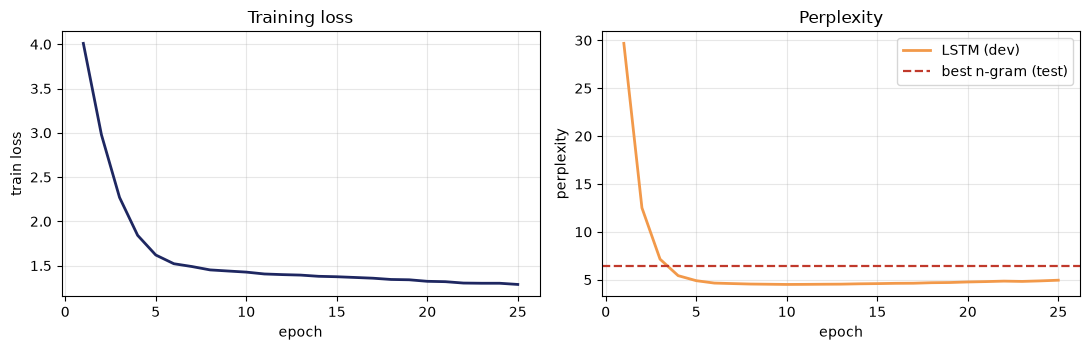

In [ ]:
import matplotlib
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt

epochs = [h[0] for h in history]
losses = [h[1] for h in history]
ppls   = [h[2] for h in history]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(epochs, losses, color="#1E2761", lw=2)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].set_title("Training loss")
ax[0].grid(alpha=.3)

ax[1].plot(epochs, ppls, color="#F2994A", lw=2, label="LSTM (dev)")
ax[1].axhline(BIGRAM_BEST_PP, color="#C0392B", ls="--", lw=1.6, label="best n-gram (test)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("perplexity"); ax[1].set_title("Perplexity")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# ส่วนที่ 11 — สร้างข้อความด้วย Temperature Sampling

$$P_T(w) = \frac{\exp(z_w / T)}{\sum_v \exp(z_v / T)}$$

- $T \to 0$ : เข้าใกล้ greedy — ปลอดภัยแต่ซ้ำซาก
- $T = 1$ : สุ่มตามการแจกแจงจริงของโมเดล
- $T > 1$ : แบนราบขึ้น — หลากหลายแต่เสี่ยงไร้สาระ

### ✏️ TODO 15 — ฟังก์ชันสร้างข้อความ

In [ ]:
@torch.no_grad()
def generate(model, temperature=1.0, max_len=20, prompt=None, seed=None):
    """
    สร้างประโยคหนึ่งประโยค
      - เริ่มจาก <s> (ต่อด้วย prompt ถ้ามี)
      - แต่ละขั้น: หาร logits ด้วย temperature -> softmax -> torch.multinomial
      - หยุดเมื่อได้ </s> หรือครบ max_len
      - คืนสตริงของคำที่สร้าง (ไม่รวม <s> และ </s>)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 15: generate()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 15</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [ ]:
@torch.no_grad()
def generate(model, temperature=1.0, max_len=20, prompt=None, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()

    tokens = [BOS] + (prompt or [])
    ids = torch.tensor([[stoi[w] for w in tokens]], device=DEVICE)
    logits, hidden = model(ids)
    out = list(prompt or [])

    for _ in range(max_len):
        probs = torch.softmax(logits[0, -1] / temperature, dim=-1)
        probs[PAD_ID] = 0.0
        probs[stoi[BOS]] = 0.0
        probs = probs / probs.sum()
        nxt = int(torch.multinomial(probs, 1).item())
        word = itos[nxt]
        if word == EOS:
            break
        out.append(word)
        logits, hidden = model(torch.tensor([[nxt]], device=DEVICE), hidden)
    return "".join(out)


print("(ใช้ seed ชุดเดียวกันทุกค่า T เพื่อเทียบกันตรง ๆ"
      " ถ้าโมเดลมั่นใจมาก ผลที่ T ต่างกันอาจออกมาเหมือนกันได้)\n")
for T in [0.3, 0.7, 1.0, 1.5, 2.0]:
    print(f"--- temperature = {T} ---")
    for i in range(3):
        print("   ", generate(model, temperature=T, seed=100 + i))
    print()

print("--- ต่อจากคำนำ 'นักศึกษา' (T = 0.7) ---")
for i in range(3):
    print("   ", generate(model, temperature=0.7, prompt=["นักศึกษา"], seed=200 + i))

# 🔍 ตรวจคำตอบ — entropy ของการแจกแจงต้องเพิ่มขึ้นตาม temperature
@torch.no_grad()
def mean_entropy(model, T):
    model.eval()
    xb_, _ = next(iter(test_loader))
    logits, _ = model(xb_.to(DEVICE))
    p = torch.softmax(logits / T, dim=-1)
    ent = -(p * torch.log(p + 1e-12)).sum(-1)
    return ent.mean().item()


print("\nentropy เฉลี่ยของการแจกแจงคำถัดไป (nats):")
ents = []
for T in [0.2, 0.5, 1.0, 2.0, 5.0]:
    e = mean_entropy(model, T)
    ents.append(e)
    print(f"  T = {T:<5} entropy = {e:.4f}")

low_T  = {generate(model, temperature=0.2, seed=s) for s in range(20)}
high_T = {generate(model, temperature=2.5, seed=s) for s in range(20)}
print(f"\nจำนวนประโยคที่ไม่ซ้ำกันจาก 20 ครั้ง: T=0.2 -> {len(low_T)} | T=2.5 -> {len(high_T)}")

assert all(a < b for a, b in zip(ents, ents[1:])), "entropy ต้องเพิ่มขึ้นตาม temperature"
print("\n✅ ผ่าน — temperature สูงขึ้น -> entropy สูงขึ้น -> ผลลัพธ์หลากหลายขึ้น")

(ใช้ seed ชุดเดียวกันทุกค่า T เพื่อเทียบกันตรง ๆ ถ้าโมเดลมั่นใจมาก ผลที่ T ต่างกันอาจออกมาเหมือนกันได้)

--- temperature = 0.3 ---
    อาจารย์เขียนวิทยานิพนธ์ทุกวัน
    แม่เรียนที่ห้องสมุดและอ่านบทความ
    พ่อกินไข่เจียวที่เชียงใหม่

--- temperature = 0.7 ---
    อาจารย์ไปโรงเรียนทุกวัน
    แม่เรียนที่ห้องสมุดและอ่านบทความ
    พ่อกินไข่เจียวที่เชียงใหม่

--- temperature = 1.0 ---
    อาจารย์ไปโรงเรียนทุกวัน
    แม่เรียนที่ตลาดและอ่านบทความ
    พ่อกินข่าวที่เชียงใหม่

--- temperature = 1.5 ---
    ไข่เจียวที่โรงเรียนง่ายมาก
    แม่เรียนที่ตลาดและอ่านบทความ
    พ่อเรียนที่โรงพยาบาลวันนี้และอ่านการบ้าน

--- temperature = 2.0 ---
    ไข่เจียวที่โรงเรียนง่ายมากแพงนี้
    แม่เรียนที่ตลาดและไป
    พ่อเรียนที่โรงพยาบาลวันเพื่อนและอ่านการบ้าน

--- ต่อจากคำนำ 'นักศึกษา' (T = 0.7) ---
    นักศึกษาเรียนที่มหาวิทยาลัยและอ่านรายงาน
    นักศึกษาไปเชียงใหม่วันนี้
    นักศึกษากินขนมที่ตลาด

entropy เฉลี่ยของการแจกแจงคำถัดไป (nats):
  T = 0.2   entropy = 0.7100
  T = 0.5   entropy = 1.0161
  T = 1.0   e

---
# ส่วนที่ 12 — ตารางเปรียบเทียบผลทั้งหมด

### ✏️ TODO 16 — สร้างตารางสรุป

In [ ]:
def summary_table():
    """
    สร้างและพิมพ์ตารางเปรียบเทียบ perplexity บนชุด test ของทุกโมเดล
    (MLE, Laplace, Add-k, Interpolation, Kneser-Ney, LSTM)
    แล้ว *คืน* ลิสต์ของ (ชื่อโมเดล, perplexity)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 16: summary_table()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 16</b> (กดเพื่อดู )</summary>

รันเซลล์ถัดไปเพื่อดูเฉลยและผลลัพธ์ที่ถูกต้อง

</details>

In [ ]:
def summary_table():
    rows = list(ngram_results) + [("LSTM LM (neural)", "LSTM LM (neural)", LSTM_TEST_PPL)]
    rows_sorted = sorted(rows, key=lambda r: r[2])
    best = rows_sorted[0][2]

    print(f"{'อันดับ':<8}{'โมเดล':<34}{'PP(test)':>12}{'เทียบกับที่ดีที่สุด':>22}")
    print("=" * 76)
    for rank, (name, _, pp) in enumerate(rows_sorted, 1):
        ratio = "-" if pp == float("inf") else f"{pp / best:.2f}x"
        print(f"{rank:<8}{name:<34}{fmt_pp(pp):>12}{ratio:>21}")
    return rows


results = summary_table()

n_zero_test = sum(len(find_zero_bigrams(s_)) for s_ in test_toks)
print("\nข้อสังเกตที่ควรเห็น:")
print(f"  1. MLE ได้ inf เพราะชุดทดสอบมี bigram ที่ไม่เคยพบในชุดฝึกอยู่ {n_zero_test} คู่")
print("  2. Laplace แก้ inf ได้ แต่ 'ขโมย' ความน่าจะเป็นจาก n-gram ที่พบจริงมากเกินไป")
print("     จึงได้ perplexity แย่ที่สุดในบรรดาโมเดลที่ smooth แล้ว")
print("  3. Add-k ที่จูน k, Interpolation และ Kneser-Ney ดีกว่า Laplace อย่างชัดเจน")
print("  4. LSTM ชนะทุกตัว เพราะแบ่งปันความรู้ผ่าน embedding และใช้บริบทได้ยาวกว่า N−1 คำ")

# 🔍 ตรวจคำตอบ
assert len(results) == 6
assert min(pp for _, _, pp in results) == LSTM_TEST_PPL, "LSTM ควรได้ perplexity ต่ำที่สุด"
assert any(pp == float("inf") for _, _, pp in results), "MLE ควรได้ inf"
print("\n✅ ผ่าน")

อันดับ  โมเดล                                 PP(test)   เทียบกับที่ดีที่สุด
1       LSTM LM (neural)                        4.2179                1.00x
2       Kneser-Ney (d=0.1)                      6.3820                1.51x
3       Add-k (k=0.01)                          6.4537                1.53x
4       Interpolation (0.98, 0.015, 0.005)      6.5225                1.55x
5       Laplace (add-1)                        13.4574                3.19x
6       MLE (ไม่ smooth)                       inf (∞)                    -

ข้อสังเกตที่ควรเห็น:
  1. MLE ได้ inf เพราะชุดทดสอบมี bigram ที่ไม่เคยพบในชุดฝึกอยู่ 9 คู่
  2. Laplace แก้ inf ได้ แต่ 'ขโมย' ความน่าจะเป็นจาก n-gram ที่พบจริงมากเกินไป
     จึงได้ perplexity แย่ที่สุดในบรรดาโมเดลที่ smooth แล้ว
  3. Add-k ที่จูน k, Interpolation และ Kneser-Ney ดีกว่า Laplace อย่างชัดเจน
  4. LSTM ชนะทุกตัว เพราะแบ่งปันความรู้ผ่าน embedding และใช้บริบทได้ยาวกว่า N−1 คำ

✅ ผ่าน


### 📊 กราฟเปรียบเทียบ

C:\Users\Satida.K\AppData\Local\Temp\ipykernel_86688\991279524.py:18: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Satida.K\AppData\Local\Temp\ipykernel_86688\991279524.py:18: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Satida.K\AppData\Local\Temp\ipykernel_86688\991279524.py:18: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Satida.K\AppData\Local\Temp\ipykernel_86688\991279524.py:18: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
c:\Users\Satida.K\anaconda3\envs\nlp\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Satida.K\anaconda3\

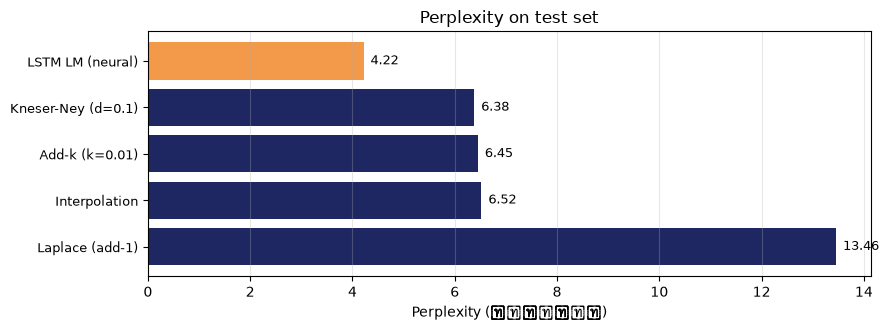

In [ ]:
# ใช้ชื่ออังกฤษในกราฟ เพราะฟอนต์เริ่มต้นของ matplotlib ไม่รองรับอักษรไทย
finite = [(en, p) for _, en, p in results if p != float("inf")]
finite.sort(key=lambda r: r[1], reverse=True)
names  = [r[0] for r in finite]
values = [r[1] for r in finite]
colors = ["#F2994A" if "LSTM" in n_ else "#1E2761" for n_ in names]

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(range(len(names)), values, color=colors)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=9)
ax.set_xlabel("Perplexity (ยิ่งต่ำยิ่งดี)")
ax.set_title("Perplexity on test set")
for b, v in zip(bars, values):
    ax.text(v + max(values) * 0.01, b.get_y() + b.get_height() / 2,
            f"{v:.2f}", va="center", fontsize=9)
ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()